### В данной лабораторной работе изучаются следующие методы решения задач условной оптимизации:
1. метод штрафных функций
2. метод барьерных функций
3. метод проекции градиента
4. метод условного градиента

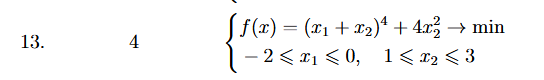

Вариант 13

In [23]:
import numpy as np
import sympy as sp
import plotly.graph_objects as go
import random 


def auxiliary_point_gd(grad, lower, upper, step_size=0.05, maxiter=1000, eps=1e-9):
    x = np.array([(lower[0] + upper[0]) / 2, (lower[1] + upper[1]) / 2])
    for _ in range(maxiter):
        c_grad = np.array([grad[0](x[0], x[1]), grad[1](x[0], x[1])])
        if np.linalg.norm(c_grad) < eps:
            break
        x_new = x - step_size * c_grad   
        x_new = np.clip(x_new, lower, upper)
        if np.linalg.norm(x_new - x) < eps:
            break
        x = x_new
    return x


def select_alpha_gd(grad, x, p, alpha=0.5, step_size=0.05, maxiter=1000, eps=1e-9):
    for _ in range(maxiter):
        x_alpha = x + alpha * p

        g = np.array([grad[0](x_alpha[0], x_alpha[1]),
                      grad[1](x_alpha[0], x_alpha[1])])
        grad_a = np.dot(g, p) 
        alpha_new = alpha - step_size * grad_a
        alpha_new = np.clip(alpha_new, 0.0, 1.0)
        if abs(alpha_new - alpha) < eps:
            break
        alpha = alpha_new
    return alpha


def cond_grad(f, x0, lower, upper, eps=1e-5, maxiter=1000, step_size=0.05):
    x = x0.copy()
    fun = sp.lambdify([x1, x2], f, "math")
    x_path = [x.copy()]
    fx = fun(x[0], x[1])
    f_path = [fx]

    x1d = sp.diff(f, x1)
    x2d = sp.diff(f, x2)
    x1d = sp.lambdify([x1, x2], x1d, "math")
    x2d = sp.lambdify([x1, x2], x2d, "math")

    for k in range(maxiter):
        x_bar = auxiliary_point_gd([x1d, x2d], lower, upper, step_size=step_size, maxiter=10000, eps = eps)
        direction = x_bar - x
        if np.linalg.norm(direction) < eps:
            break

        alpha = select_alpha_gd([x1d, x2d], x, direction, step_size=step_size, maxiter=10000, eps = eps)

        x = x + alpha * direction
        x_path.append(x.copy())
        fx = fun(x[0], x[1])
        f_path.append(fx)

    return x_path, f_path, k


x1, x2 = sp.symbols('x1, x2')
f = (x1+x2)**4 + 4*x2**2
random.seed(42)
p_list = ([-2, 3], [random.uniform(-2, 0),  random.uniform(1, 3)])
e_list = (0.1, 1e-6)
lower = [-2, 1]
upper = [0, 3]
x1_range = np.linspace(-3, 1, 100)
x2_range = np.linspace(0, 4, 100)

x1_range = np.linspace(-5, 5, 100)
x2_range = np.linspace(-5, 5, 100)

x, y = np.meshgrid(x1_range, x2_range)
fu = (x+y)**4 + 4*y**2
fig = go.Figure(data=[go.Contour(
    zmax = 5000, zmin = 0,
    z=fu, x=x1_range, y=x2_range, colorscale='Jet',
    contours=dict(
        coloring = 'heatmap',
        showlabels = True,
        labelfont = dict(
            size = 12,
            color = 'white',
        )
    ) 
)])
fig.update_layout(title=f'(x1+x2)^4 + 4*x2^2') 
fig.add_shape(type="rect",
    x0=-2, y0=1, x1=0, y1=3,
    line=dict(color="RoyalBlue"),)

# method visualize

for point in p_list:
    for e in e_list:
        print(f'point = {point}')
        ans = cond_grad(f, point, lower, upper, eps=e)
        print(ans[0][-1], ans[1][-1], ans[2])
        fig.add_trace(go.Scatter(x=[i[0] for i in ans[0]], y=[i[1] for i in ans[0]], name=f'точка {point}'))
fig.show()


point = [-2, 3]
[-1.2  1. ] 4.0016 1
point = [-2, 3]
[-1.01709945  1.        ] 4.000000085492514 1
point = [-0.7211464030842325, 1.0500215104453339]
[-1.1401433   1.00625269] 4.050499261339323 3
point = [-0.7211464030842325, 1.0500215104453339]
[-1.01709945  1.        ] 4.000000085492514 1
